In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

In [3]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (20640, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [9]:
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (20640, 8)
Target Shape: (20640,)


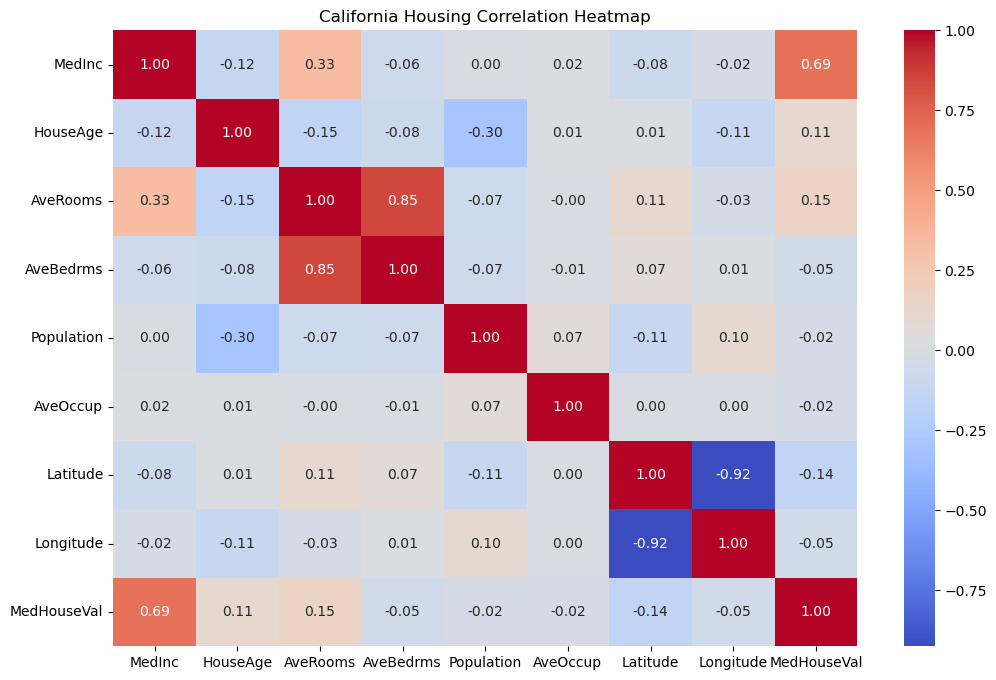

In [11]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("California Housing Correlation Heatmap")
plt.show()

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (16512, 8)
Testing Data: (4128, 8)


In [27]:
def create_pipeline(model):

    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('interaction', PolynomialFeatures(
            degree=2,
            interaction_only=True,
            include_bias=False
        )),
        ('scaler', StandardScaler()),
        ('model', model)
    ])

In [29]:
ols_model = create_pipeline(LinearRegression())

ols_model.fit(X_train, y_train)

ols_predictions = ols_model.predict(X_test)

In [31]:
ridge_pipeline = create_pipeline(Ridge())

ridge_params = {
    'model__alpha': [0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

ridge_predictions = ridge_grid.predict(X_test)

print("Best Ridge Parameters:", ridge_grid.best_params_)

Best Ridge Parameters: {'model__alpha': 1}


In [39]:
lasso_pipeline = create_pipeline(Lasso(max_iter=20000))

lasso_params = {
    'model__alpha': [0.001, 0.01, 0.1, 1, 10]
}

lasso_grid = GridSearchCV(
    lasso_pipeline,
    lasso_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

lasso_predictions = lasso_grid.predict(X_test)

print("Best Lasso Parameters:", lasso_grid.best_params_)

Best Lasso Parameters: {'model__alpha': 0.01}


In [41]:
models = {
    'OLS': ols_predictions,
    'Ridge': ridge_predictions,
    'Lasso': lasso_predictions
}

results = []

for name, predictions in models.items():

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,RMSE,MAE,R2 Score
0,OLS,0.703347,0.480861,0.622486
1,Ridge,0.730526,0.496303,0.592747
2,Lasso,0.751367,0.532891,0.569178


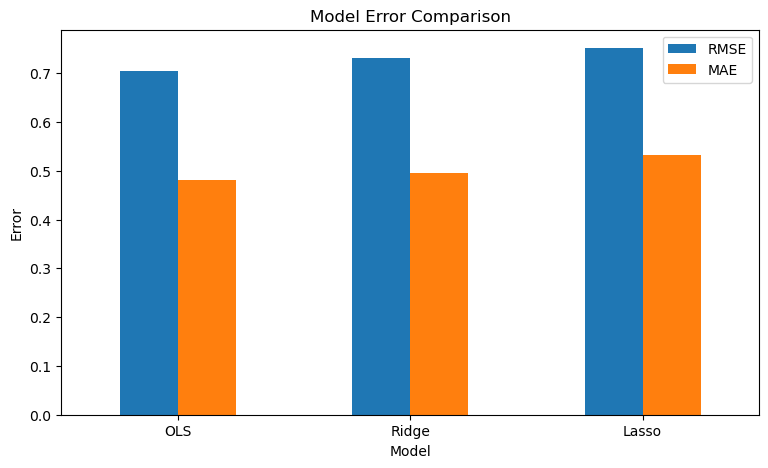

In [43]:
results_df.set_index('Model')[['RMSE', 'MAE']].plot(
    kind='bar',
    figsize=(9, 5)
)
plt.title("Model Error Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()

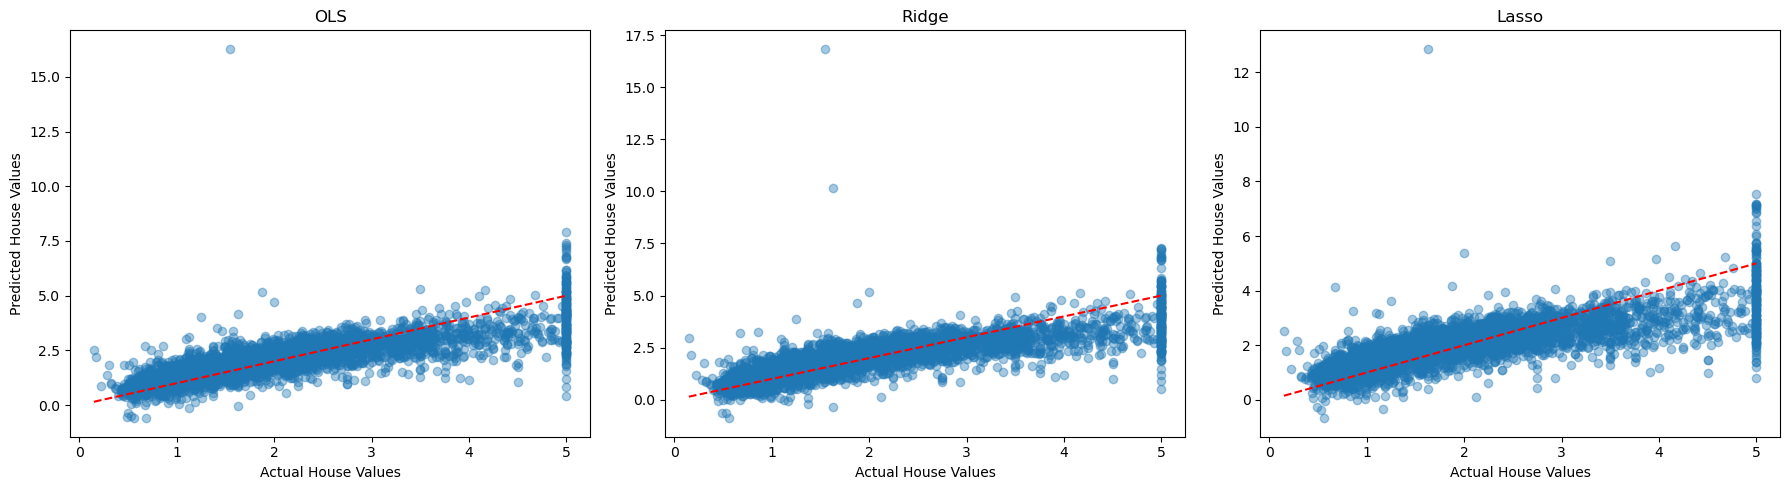

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, predictions) in zip(axes, models.items()):

    ax.scatter(y_test, predictions, alpha=0.4)

    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--'
    )

    ax.set_title(name)
    ax.set_xlabel("Actual House Values")
    ax.set_ylabel("Predicted House Values")

plt.tight_layout()
plt.show()

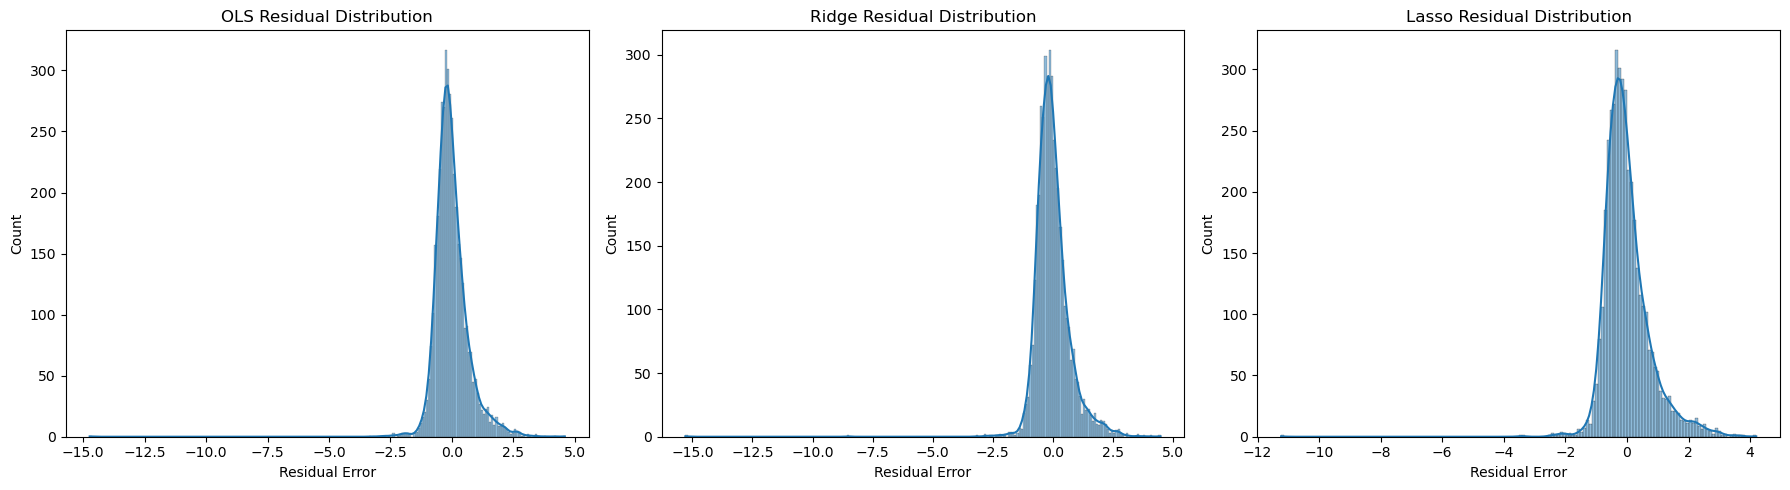

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, predictions) in zip(axes, models.items()):

    residuals = y_test - predictions

    sns.histplot(
        residuals,
        kde=True,
        ax=ax
    )

    ax.set_title(name + " Residual Distribution")
    ax.set_xlabel("Residual Error")

plt.tight_layout()
plt.show()

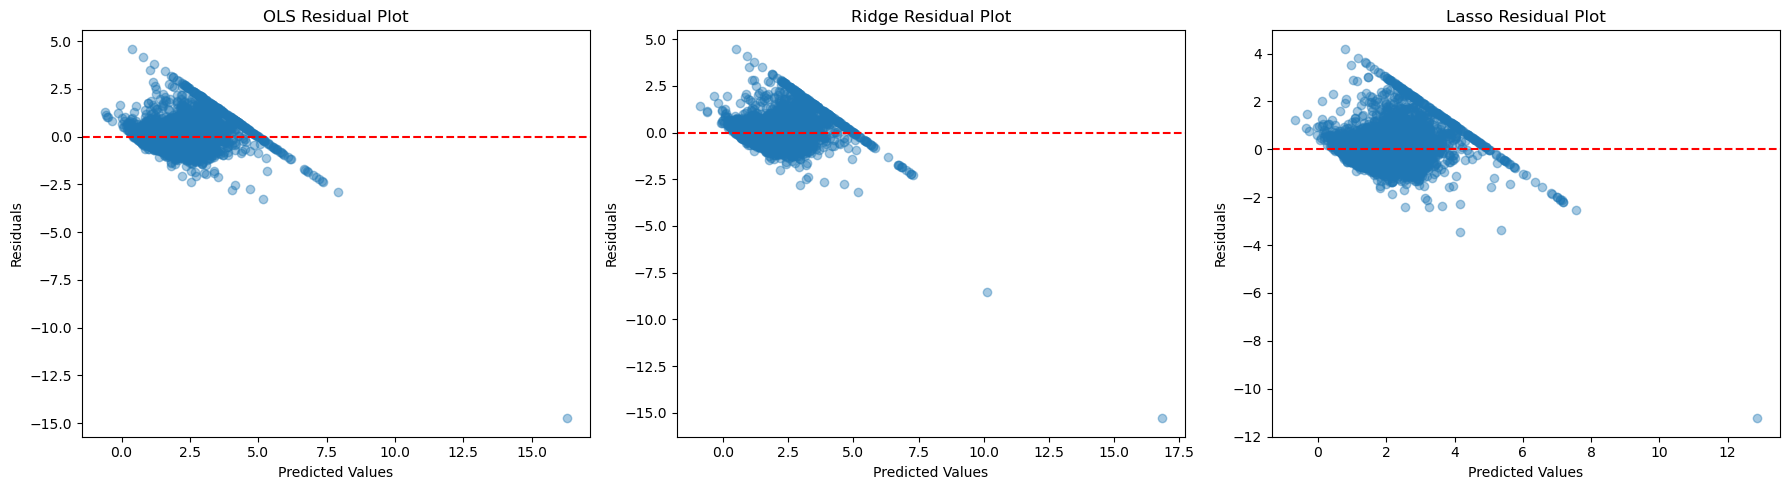

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(axes, models.items()):

    residuals = y_test - predictions

    ax.scatter(predictions, residuals, alpha=0.4)
    ax.axhline(y=0, color='red', linestyle='--')

    ax.set_title(name + " Residual Plot")
    ax.set_xlabel("Predicted Values")
    ax.set_ylabel("Residuals")

plt.tight_layout()
plt.show()

In [ ]:
best_model = results_df.loc[results_df['RMSE'].idxmin()]

print("Best Performing Model:", best_model['Model'])
print("RMSE:", best_model['RMSE'])
print("MAE:", best_model['MAE'])
print("R2 Score:", best_model['R2 Score'])